# Continuous Assurance: Maintaining the Safety Case as Code

**Module 08 · Standards, Regulation and Safety Case** · Notebook 6 of 6

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/08_Standards_Regulation_and_Safety_Case/06_continuous_assurance.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Advanced | [Safety case with GSN](04_safety_case_gsn.ipynb), [Capstone: pedestrian AEB](05_capstone_aeb_from_requirement_to_release.ipynb), [Field safety monitoring](../07_Runtime_Assurance_and_Operations/05_field_safety_monitoring.ipynb) | UL 4600 (3rd ed., 2023), ISO/TS 5083:2025, ISO 21448:2022, ISO/PAS 8800:2024, GSN Community Standard v3 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Explain why a safety case written once becomes wrong without anyone editing it, and which changes cause this.
2. State what UL 4600, ISO/TS 5083, ISO 21448 and ISO/PAS 8800 say about keeping the argument valid after release, and how much of that is publicly verifiable.
3. Express an argument as code: GSN nodes in YAML, acceptance criteria fixed in the argument, evidence records written by the notebooks that compute them, and explicit status propagation rules.
4. Evaluate the course's pedestrian AEB case live and read its statuses: *supported, assumed, undeveloped, inconclusive, stale, missing, challenged*.
5. Trace how a detector update, a dataset shift or a field safety performance indicator (SPI) crossing its threshold turns a claim red, and how a CI job catches it on every pull request.
6. Name what this automation cannot do: a green status is evidence that criteria are met, not that the argument is sound.

## 1. Why static safety cases rot

A safety case is an argument *at a configuration*: this model version, this dataset, this ODD, these field data. Every claim silently depends on four things, and each changes over the product's life:

| What changes | Example in the AEB case | What breaks | How the case-as-code notices |
|---|---|---|---|
| Producer code or model | detector retrained, threshold tuned | the evidence describes a different system | **stale**: the hash of the producing notebook's code differs from the hash stored with the evidence |
| Data | new test set, another city, night | the measured value changes | **challenged**: the criterion fails on regenerated evidence |
| The world | field crash rate rises | an assumption of the argument no longer holds | **challenged / inconclusive**: an SPI interval crosses or straddles its threshold |
| Time | SPI not refreshed | the evidence no longer describes current operation | **stale**: evidence older than the age limit of its solution |

A document cannot notice any of these. The remedy that this notebook implements is not new in principle: Denney, Pai and Habli (2015) proposed *dynamic safety cases* that are updated through life from operational data, and Assurance 2.0 (Bloomfield & Rushby, 2020) argues for continuous, incremental assurance that treats defeaters and counter-evidence explicitly. What is new here is only that the course's own notebooks are the evidence producers, so the whole loop runs and can be inspected.

## 2. What the standards say about maintaining the argument

Precise wording of these documents is paywalled. The table states only what could be verified from public sources (as of October 2026), and how.

| Document | What it says about the operation phase | How verified |
|---|---|---|
| **UL 4600**, 3rd ed. (17 March 2023) | Safety-case-centric standard for autonomous products. It requires **safety performance indicators**: metrics with thresholds, each tied to a claim of the safety case, used to detect that a claim is no longer valid and to feed field data back into the case. Leading and lagging SPIs are distinguished. | UL announcement of edition 3; Koopman (2023); Koopman's SPI lecture slides (2022): "SPI measures validity of a safety case claim … a SPI value violation means safety case is invalid"; Ratiu et al. (2024) quote the standard's SPI definition. Clause numbers not verified. |
| **ISO/TS 5083:2025**, ed. 1 (29 April 2025) | Guidance "for achieving and demonstrating safety" of SAE Level 3 and 4 ADS, considering "safety by design, verification and validation, and post deployment activities"; it also outlines cybersecurity considerations. | Public abstract (national standards body store). Whether and how it prescribes safety-case maintenance could not be verified from public text. |
| **ISO 21448:2022** clause 13 | Clause 13 *Operation phase activities* (13.1 objectives, 13.2 general, 13.3 topics for observation): a field monitoring process to maintain the SOTIF after release. | Public table of contents; content summarised from secondary literature only. |
| **ISO/PAS 8800:2024** clause 14 | *Measures during operation* for AI systems (field monitoring, data collection, controlled updates), next to clause 8 *Assurance argument for AI systems*. | Public table of contents (see [06-01](../06_AI_Safety_ISO_PAS_8800/01_ai_safety_standards.ipynb)). |

The common idea is simple and old: the argument is part of the product and must be kept true as the product and its environment change. None of these documents prescribes *how* to automate it; the method below is one engineering answer.

## 3. The method: argument, criteria and evidence as code

Three artefacts, each under version control next to the notebooks:

1. **Argument** — [`safety_case/aeb_pedestrian.yaml`](../safety_case/aeb_pedestrian.yaml): GSN goals, strategies, solutions, context, assumptions and justifications with *SupportedBy* and *InContextOf* links. Each solution names an evidence record and an **acceptance criterion**, e.g. `recall_lower_95 >= 0.90`. Criteria live in the argument, not in the producer: the team that measures does not decide what counts as enough.
2. **Evidence** — `safety_case/evidence/<id>.json`: values, units, sample size, producing notebook, a hash of that notebook's code cells, timestamp, dataset and licence. A notebook writes it with one call, `avsafety.assurance.record_evidence(...)`, as its last code cell.
3. **Evaluator** — `avsafety.assurance`: computes every node's status from the evidence that exists now, with explicit rules. Normative values (ASIL, PMHF target, permitted decompositions, CAL) are computed with `avsafety.iso26262` and `avsafety.iso21434` from the HARA and TARA entries in the YAML, never typed into a criterion.

**Status propagation.** Statuses are ordered from best to worst: *supported < assumed < undeveloped < inconclusive < stale < missing < challenged*.

| Rule | Statement |
|---|---|
| P1 | A **solution** is *missing* if its evidence or metric does not exist, else *stale* if its producer changed (or it is older than its age limit), else *supported* if the criterion holds. If not, it is *challenged*; when a `refute` condition is given, it is *challenged* only if the refutation holds and *inconclusive* otherwise (an interval straddling a threshold). |
| P2 | An **assumption** is *assumed* unless it has its own check; a failed check *challenges* it (an undercutting defeater). |
| P3 | A **goal or strategy** takes the worst status of its *SupportedBy* children and its *InContextOf* assumptions. Support is conjunctive: a goal is supported only if every child is, and any challenged child challenges it. Context and justification nodes do not propagate. |
| P4 | A goal marked **undeveloped**, or a leaf goal without support (an integrity error), is *undeveloped*. |

**Confidence** is reported as *n|m*: of the *m* checks identified below a node (solutions and assumptions), *n* passed. This is the Baconian measure of eliminative argumentation (Goodenough, Weinstock & Klein, 2013): it counts doubts removed, it is not a probability.

In [1]:
# Course toolkit. Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[assurance] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import assurance as A
from avsafety import validation as VAL

import copy
import datetime as dt
import json
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import SVG, Markdown, display

AS_OF = dt.date(2026, 10, 29)      # fixed evaluation date so that the age rules are reproducible
pd.set_option("display.max_colwidth", 110)

REPO = A.find_repo_root()
if REPO is not None:
    CASE_FILE = REPO / "safety_case" / "aeb_pedestrian.yaml"
else:                               # Colab: fetch the case and its committed evidence from GitHub
    RAW = "https://raw.githubusercontent.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/main/safety_case/"
    work = Path(tempfile.mkdtemp()) / "safety_case"
    (work / "evidence").mkdir(parents=True)
    urllib.request.urlretrieve(RAW + "aeb_pedestrian.yaml", work / "aeb_pedestrian.yaml")
    import yaml
    for n in yaml.safe_load((work / "aeb_pedestrian.yaml").read_text())["nodes"]:
        if n.get("evidence") and not (work / "evidence" / f"{n['evidence']}.json").exists():
            urllib.request.urlretrieve(RAW + f"evidence/{n['evidence']}.json", work / "evidence" / f"{n['evidence']}.json")
    CASE_FILE = work / "aeb_pedestrian.yaml"
case = A.load_case(CASE_FILE)
print(f"Case '{case.title}': {len(case.nodes)} nodes, evidence in {case.evidence_dir.name}/;",
      "producer hashes checked against the repository" if case.root else "outside the repository: producer hashes cannot be checked")

Case 'Pedestrian AEB - assurance case': 55 nodes, evidence in evidence/; producer hashes checked against the repository


### 3.1 What the files look like

One branch of the argument, and the evidence record that its solution references. The record was written by the last code cell of [04-03 OOD monitoring](../04_SOTIF_ISO21448/03_ood_monitoring_as_safety_measure.ipynb).

In [2]:
lines = CASE_FILE.read_text().splitlines()
start = next(i for i, l in enumerate(lines) if l.strip() == "- id: G3.3")
print("\n".join(lines[start:start + 18]))
print("\n--- safety_case/evidence/ood-monitor-kitti.json")
print((case.evidence_dir / "ood-monitor-kitti.json").read_text())

  - id: G3.3
    type: Goal
    text: "Degraded camera conditions (fog, low light) are detected at runtime so that the function degrades"
    in_context_of: [A3.3]
    supported_by: [Sn3.3]
  - id: A3.3
    type: Assumption
    text: "Physically based fog and low light rendered on real KITTI frames represent real degradations"
  - id: Sn3.3
    type: Solution
    text: "OOD monitor: requirement R-MON-1, TPR >= 0.90 at 95 % confidence (04-03)"
    evidence: ood-monitor-kitti
    criterion: "tpr_lower_95 >= 0.90"

  # ---------------- ISO/PAS 8800
  - id: G4
    type: Goal
    text: "ML-specific insufficiencies of the detector are controlled (ISO/PAS 8800)"

--- safety_case/evidence/ood-monitor-kitti.json
{
  "schema": "avsafety.evidence/1",
  "id": "ood-monitor-kitti",
  "title": "OOD monitor on degraded KITTI frames: requirement-based threshold, held-out test frames",
  "values": {
    "signal": "feature k-NN distance",
    "auroc_test": 0.975556,
    "tpr_detected": 30,
    "tpr_n": 3

## 4. Evaluate the AEB case live

First the **integrity check**, which is what CI enforces: the argument is well-formed GSN, every referenced notebook and evidence file exists, evidence follows the schema, every criterion can be evaluated, and no evidence is stale. Then the **evaluation**, whose statuses are reported, not enforced: an honest case may say *do not release*.

In [3]:
issues = case.check()
errors = [i for i in issues if i.level == "error"]
print(f"Integrity: {len(errors)} error(s), {len(issues) - len(errors)} warning(s)")
for i in issues:
    print("  ", i)

ev = case.evaluate(as_of=AS_OF)
print(f"\nTop claim G1: {ev.top.status.upper()} (confidence {ev.top.confidence}); goal statuses {ev.counts()}")
d = case.derived()
print(f"Derived with avsafety: SG-01 ASIL {d['SG-01.asil']} (PMHF target {d['SG-01.pmhf_target_per_h']:.0e}/h, "
      f"FTTI {d['SG-01.ftti_ms']} ms), SG-02 ASIL {d['SG-02.asil']} (FTTI {d['SG-02.ftti_ms']} ms), "
      f"CAL {[d[f'TS-0{i}.cal'] for i in range(1, 5)]} for TS-01..04")

Integrity: 0 error(s), 0 warning(s)

Top claim G1: CHALLENGED (confidence 11|20); goal statuses {'supported': 5, 'assumed': 3, 'undeveloped': 3, 'inconclusive': 2, 'challenged': 8}
Derived with avsafety: SG-01 ASIL D (PMHF target 1e-08/h, FTTI 300 ms), SG-02 ASIL B (FTTI 500 ms), CAL [4, 4, 2, 2] for TS-01..04


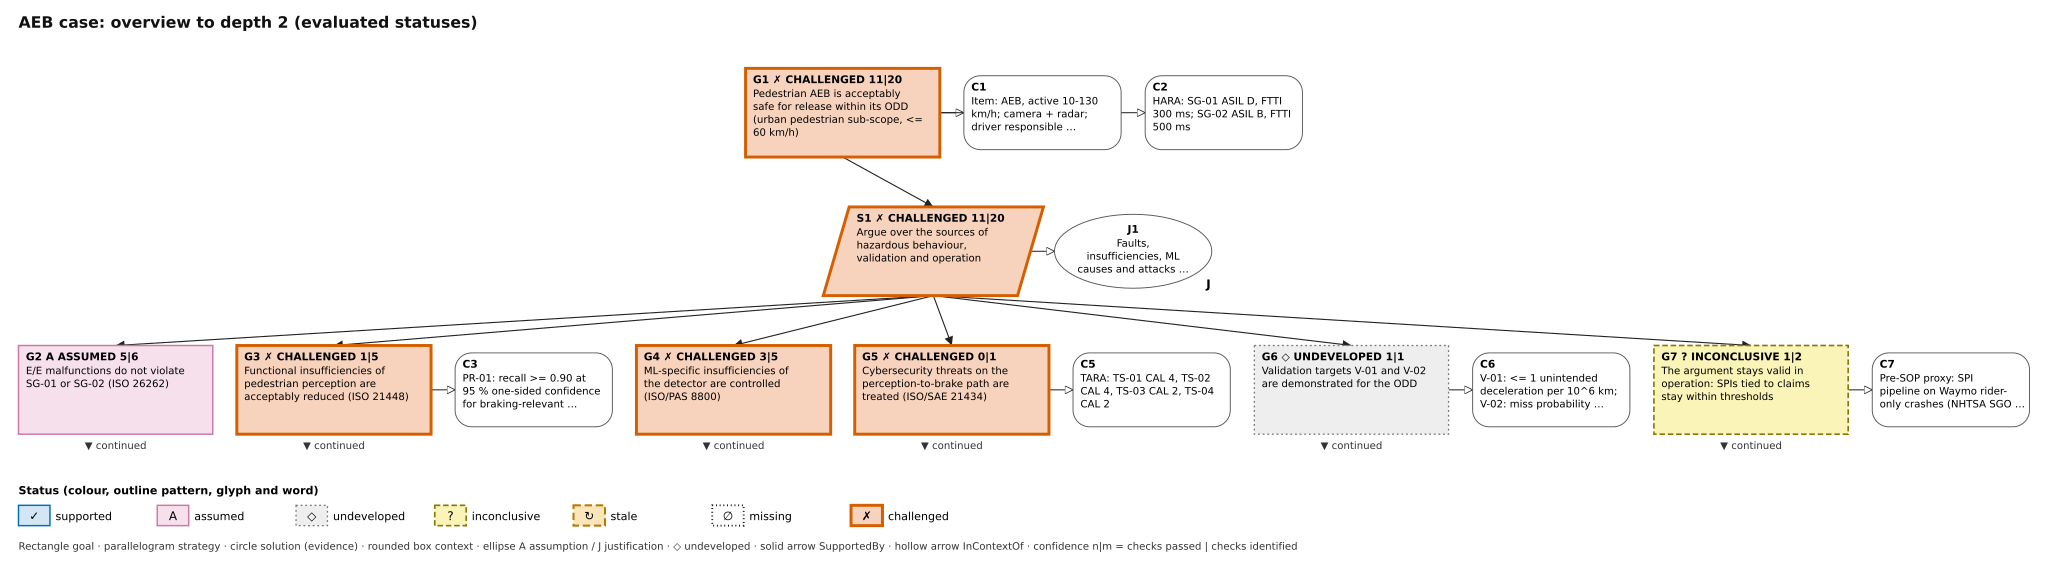

In [4]:
display(SVG(ev.to_svg(max_depth=2, title="AEB case: overview to depth 2 (evaluated statuses)")))

The overview already answers the release question: three branches (G3, G4, G5) are *challenged*, the ISO 26262 branch is only *assumed*, validation is *undeveloped* and field monitoring is *inconclusive*. The table below gives every claim with its criterion, the observed value and the producing notebook. It agrees with the capstone's GSN table and release checklist ([08-05 §8-§9](05_capstone_aeb_from_requirement_to_release.ipynb)), because both read the same computations, with one deliberate difference: assumptions are explicit nodes here, so G2.1, which the capstone lists as supported, is *assumed* until the independence of the two channels is backed by a DFA record. And this table is recomputed whenever the evidence changes.

In [5]:
display(Markdown(ev.to_markdown(link_base="../", types=("Goal",))))

| Node | Type | Claim / evidence | Status | Criterion → observed | Producer | Confidence |
|---|---|---|---|---|---|---|
| G1 | Goal | Pedestrian AEB is acceptably safe for release within its ODD (urban pedestrian sub-scope, <= 60 km/h) | ✗ **challenged** |  |  | 11\|20 |
| G2 | Goal | E/E malfunctions do not violate SG-01 or SG-02 (ISO 26262) | A **assumed** |  |  | 5\|6 |
| G2.0 | Goal | Every ASIL-rated hazardous event has a safety goal; ASIL and FTTI used in the release analysis match the HARA | ✓ supported |  |  | 1\|1 |
| G2.1 | Goal | SG-01 (ASIL D): E/E faults do not cause unintended AEB deceleration | A **assumed** |  |  | 3\|4 |
| G2.2 | Goal | SG-02 (ASIL B) E/E part: loss of perception is detected within 500 ms | ✓ supported |  |  | 1\|1 |
| G3 | Goal | Functional insufficiencies of pedestrian perception are acceptably reduced (ISO 21448) | ✗ **challenged** |  |  | 1\|5 |
| G3.1 | Goal | PR-01 holds in the specified ODD (<= 60 km/h) | ✗ **challenged** |  |  | 0\|2 |
| G3.2 | Goal | PR-01 holds in a restricted ODD that is enforced by design | ✗ **challenged** |  |  | 0\|1 |
| G3.3 | Goal | Degraded camera conditions (fog, low light) are detected at runtime so that the function degrades | A **assumed** |  |  | 1\|2 |
| G4 | Goal | ML-specific insufficiencies of the detector are controlled (ISO/PAS 8800) | ✗ **challenged** |  |  | 3\|5 |
| G4.1 | Goal | Detector scores are calibrated where fusion uses them as probabilities | ✓ supported |  |  | 2\|2 |
| G4.2 | Goal | A score threshold bounds the pedestrian miss rate at alpha = 0.10 (split conformal) | ✗ **challenged** |  |  | 0\|1 |
| G4.3 | Goal | Distance intervals cover the true pedestrian distance with probability >= 0.90 | ✗ **challenged** |  |  | 1\|2 |
| G5 | Goal | Cybersecurity threats on the perception-to-brake path are treated (ISO/SAE 21434) | ✗ **challenged** |  |  | 0\|1 |
| G6 | Goal | Validation targets V-01 and V-02 are demonstrated for the ODD | ◇ **undeveloped** |  |  | 1\|1 |
| G6.0 | Goal | The rate bounds used for V-01 and V-02 are conservative (exact Poisson intervals) | ✓ supported |  |  | 1\|1 |
| G6.1 | Goal | Fleet exposure and proving-ground encounters demonstrate V-01 and V-02 | ◇ **undeveloped** |  | [08_statistical_safety_validation](../06_AI_Safety_ISO_PAS_8800/08_statistical_safety_validation.ipynb) | 0\|0 |
| G6.2 | Goal | Executed scenarios cover the ODD pairwise (100 %) | ◇ **undeveloped** |  | [04_simulation_based_validation](../04_SOTIF_ISO21448/04_simulation_based_validation.ipynb) | 0\|0 |
| G7 | Goal | The argument stays valid in operation: SPIs tied to claims stay within thresholds | ? **inconclusive** |  |  | 1\|2 |
| G7.1 | Goal | Injury-crash rate <= 50 % of the matched human benchmark (lagging SPI) | ✓ supported |  |  | 1\|1 |
| G7.2 | Goal | Crashes involving a VRU <= 0.10 per 10^6 miles (lagging SPI, illustrative threshold) | ? **inconclusive** |  |  | 0\|1 |

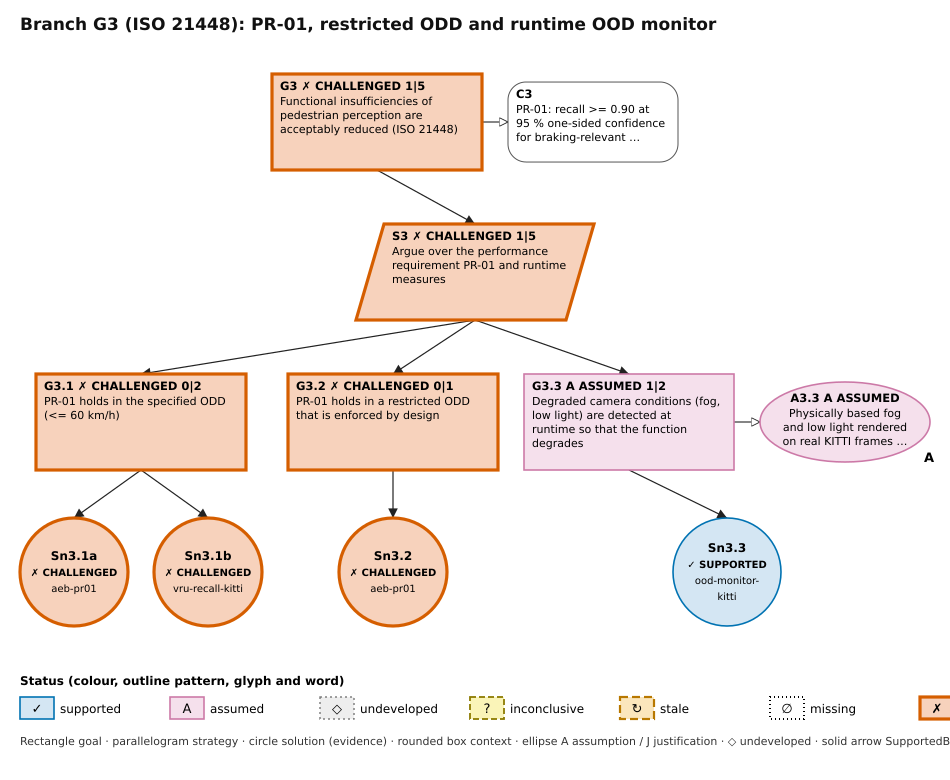

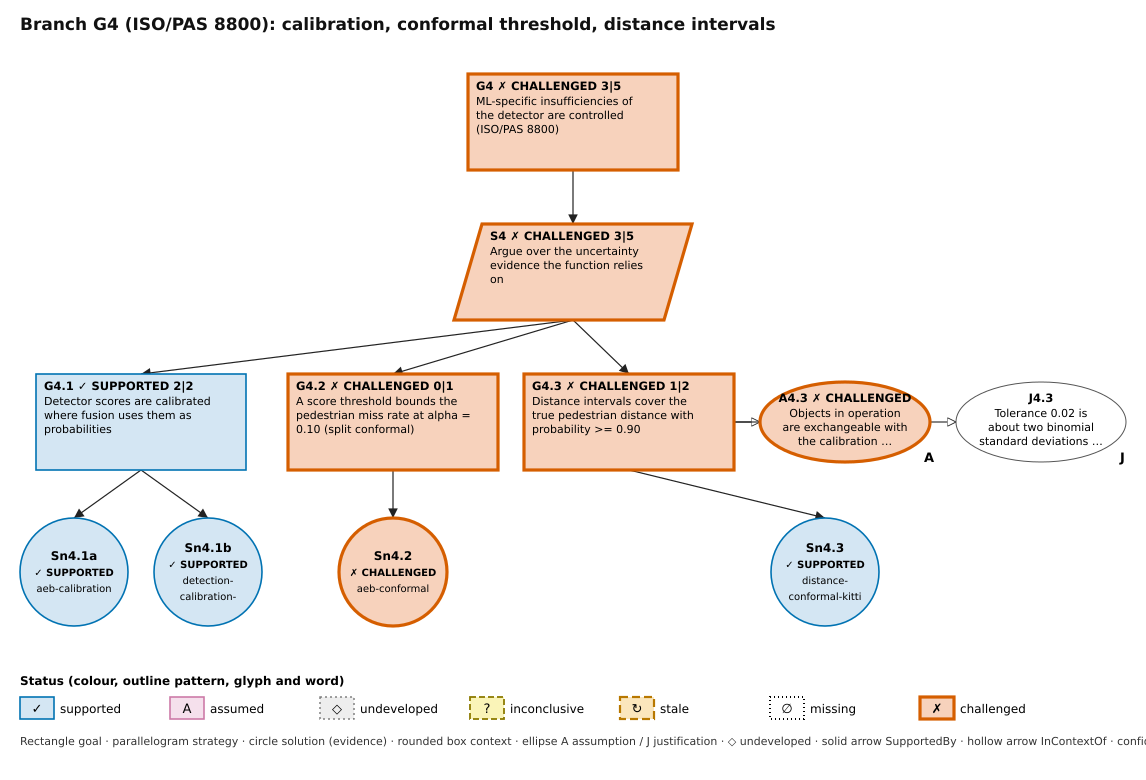

,node,status,criterion,reason
0,Sn2.0,supported,uncovered_events == 0 and sg01_asil == SG-01.asil and sg02_asil == SG-02.asil and sg01_ftti_ms == SG-01.ft...,uncovered_events = 0 == 0; sg01_asil = D == D (SG-01.asil); sg02_asil = B == B (SG-02.asil); sg01_ftti_ms ...
1,A2.1,assumed,,assumption without supporting evidence
2,Sn2.1a,supported,decomposition_sg01 in SG-01.decompositions,"decomposition_sg01 = [B(D), B(D)] in [[C(D), A(D)], [B(D), B(D)], [D(D), QM(D)]] (SG-01.decompositions)"
3,Sn2.1b,supported,fta_top_event_per_h < SG-01.pmhf_target_per_h,fta_top_event_per_h = 8e-10 < 1e-08 (SG-01.pmhf_target_per_h)
4,Sn2.1c,supported,fhti_max_sg01_ms <= SG-01.ftti_ms,fhti_max_sg01_ms = 200 <= 300 (SG-01.ftti_ms)
5,Sn2.2,supported,fhti_max_sg02_ms <= SG-02.ftti_ms,fhti_max_sg02_ms = 300 <= 500 (SG-02.ftti_ms)
6,Sn3.1a,challenged,recall_lower_95 >= 0.90,criterion not met: recall_lower_95 = 0.646 >= 0.9
7,Sn3.1b,challenged,max_recall_any_threshold >= 0.90,criterion not met: max_recall_any_threshold = 0.556 >= 0.9
8,Sn3.2,challenged,v_star_kmh != null,criterion not met: v_star_kmh = null != null
9,A3.3,assumed,,assumption without supporting evidence


In [6]:
for branch, title in [("G3", "Branch G3 (ISO 21448): PR-01, restricted ODD and runtime OOD monitor"),
                      ("G4", "Branch G4 (ISO/PAS 8800): calibration, conformal threshold, distance intervals")]:
    display(SVG(ev.to_svg(root=branch, title=title)))
sol = pd.DataFrame([r for r in ev.rows() if r["type"] in ("Solution", "Assumption")])
display(sol[["node", "status", "criterion", "reason"]])

**Reading the result.** Three kinds of red are visible, and they call for different actions:

* **Rebutting defeaters** (the claim is false on current evidence): PR-01 recall lower bound below 0.90 (G3.1), no conformal threshold (G4.2), an open cybersecurity risk (G5).
* **An undercutting defeater** (the inference fails): G4.3's own evidence meets its criterion, but assumption A4.3, *objects in operation are exchangeable with the calibration objects*, is contradicted by the coverage on truncated objects in [06-05](../06_AI_Safety_ISO_PAS_8800/05_conformal_prediction.ipynb). The claim is challenged although its solution is green. This is exactly the case a list of KPIs would miss.
* **Not yet argued**: validation (G6.1, G6.2) is undeveloped, and an unverified assumption (A2.1, A3.3) leaves its goal *assumed*, never fully supported.

## 5. The loop: evidence changes, a claim flips

### 5.1 Evidence is regenerated by the notebook that computes it

Every record carries the hash of its producer's code cells. The table compares the stored hash with the hash of the notebook as it is now; executing a notebook rewrites its record with the current hash.

In [7]:
rows = []
for eid, rec in sorted(ev.evidence.items()):
    nb = rec["producer"]["notebook"]
    now = A.notebook_code_hash(case.root / nb) if case.root else None
    rows.append({"evidence": eid, "producer": nb.split("/")[-1], "recorded (UTC)": rec["recorded_at"][:16],
                 "stored hash": rec["producer"]["code_hash"][7:], "current hash": now[7:] if now else "n/a",
                 "state": "current" if now == rec["producer"]["code_hash"] else ("unknown" if now is None else "STALE")})
display(pd.DataFrame(rows))

,evidence,producer,recorded (UTC),stored hash,current hash,state
0,aeb-calibration,05_capstone_aeb_from_requirement_to_release.ipynb,2026-10-29T08:47,2def87cb6e6261ba,2def87cb6e6261ba,current
1,aeb-conformal,05_capstone_aeb_from_requirement_to_release.ipynb,2026-10-29T08:47,2def87cb6e6261ba,2def87cb6e6261ba,current
2,aeb-fsc,05_capstone_aeb_from_requirement_to_release.ipynb,2026-10-29T08:47,2def87cb6e6261ba,2def87cb6e6261ba,current
3,aeb-hara,05_capstone_aeb_from_requirement_to_release.ipynb,2026-10-29T08:47,2def87cb6e6261ba,2def87cb6e6261ba,current
4,aeb-pr01,05_capstone_aeb_from_requirement_to_release.ipynb,2026-10-29T08:47,2def87cb6e6261ba,2def87cb6e6261ba,current
5,aeb-tara,05_capstone_aeb_from_requirement_to_release.ipynb,2026-10-29T08:47,2def87cb6e6261ba,2def87cb6e6261ba,current
6,detection-calibration-kitti,04_calibration.ipynb,2026-10-29T08:44,b355582a8eaadb46,b355582a8eaadb46,current
7,distance-conformal-kitti,05_conformal_prediction.ipynb,2026-10-29T08:44,9f1766b5699c280d,9f1766b5699c280d,current
8,field-spi-waymo,05_field_safety_monitoring.ipynb,2026-10-29T08:47,b9c9830c48f3e137,b9c9830c48f3e137,current
9,ood-monitor-kitti,03_ood_monitoring_as_safety_measure.ipynb,2026-10-29T08:42,25b7c51ee034baab,25b7c51ee034baab,current


Regeneration is deterministic where the producer is: below, the PR-01 lower bound is recomputed from the stored counts with the same `avsafety.validation.poisson_upper_bound` the capstone uses, recorded into a scratch directory, and the case is re-evaluated. Nothing flips, which is what CI checks after every notebook run.

In [8]:
scratch = Path(tempfile.mkdtemp())
fresh = copy.deepcopy(ev.evidence)
pr = fresh["aeb-pr01"]["values"]
lower = max(0.0, 1 - VAL.poisson_upper_bound(fresh["aeb-pr01"]["n"] - pr["detected"], fresh["aeb-pr01"]["n"], 0.95))  # as in 08-05
new = A.record_evidence("aeb-pr01", notebook=fresh["aeb-pr01"]["producer"]["notebook"], evidence_dir=scratch,
                        dataset="KITTI object detection, 40 training frames (left camera)", licence="CC BY-NC-SA 3.0",
                        n=fresh["aeb-pr01"]["n"], confidence=0.95, **{**pr, "recall_lower_95": lower})
fresh["aeb-pr01"] = dict(new)
print(f"Recomputed recall lower bound {lower:.3f} (stored {pr['recall_lower_95']:.3f}); written to {new['_written_to']}")
print("Status changes:", A.diff(ev, case.evaluate(fresh, as_of=AS_OF)) or "none")

Recomputed recall lower bound 0.646 (stored 0.646); written to /tmp/tmpwx2pe04z/aeb-pr01.json
Status changes: none


### 5.2 A code change makes evidence stale

Suppose someone edits the OOD monitor notebook, here by tightening the detector's operating threshold, and does not re-run it. The stored evidence no longer describes the code. The demonstration uses a scratch copy of the repository's notebooks, so nothing in the repository changes.

In [9]:
if case.root is not None:
    sandbox = Path(tempfile.mkdtemp())
    shutil.copy(case.root / "pyproject.toml", sandbox)
    used = {r["producer"]["notebook"] for r in ev.evidence.values()} | {n.notebook for n in case.nodes.values() if n.notebook}
    for nb in used:                                   # every notebook the case refers to
        (sandbox / nb).parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(case.root / nb, sandbox / nb)
    ood = sandbox / "04_SOTIF_ISO21448/03_ood_monitoring_as_safety_measure.ipynb"
    nbj = json.loads(ood.read_text())
    cell = next(c for c in nbj["cells"] if c["cell_type"] == "code" and "SCORE_THR = " in "".join(c["source"]))
    src = "".join(cell["source"])
    assert "SCORE_THR = 32.0, 0.65, 0.3" in src
    cell["source"] = src.replace("SCORE_THR = 32.0, 0.65, 0.3", "SCORE_THR = 32.0, 0.65, 0.4")
    ood.write_text(json.dumps(nbj))
    edited = A.AssuranceCase(case.nodes.values(), name=case.name, title=case.title, hara=case.hara, tara=case.tara,
                             root=sandbox, evidence_dir=case.evidence_dir)
    ev_edit = edited.evaluate(ev.evidence, as_of=AS_OF)
    for f in A.diff(ev, ev_edit):
        print(f"{f['node']:7s} {f['old']:>11s} -> {f['new']:<11s} {f['reason']}")
    print("Integrity errors now:", [str(i) for i in edited.check(ev.evidence) if i.level == "error"])
else:
    print("Outside the repository the producer notebooks are not available; run this cell in a clone.")

G3.3        assumed -> stale       from Sn3.3
Sn3.3     supported -> stale       producer 03_ood_monitoring_as_safety_measure.ipynb changed since the evidence was recorded (25b7c51e -> 57c07616)


Integrity errors now: ['ERROR   Sn3.3: evidence ood-monitor-kitti is stale: 04_SOTIF_ISO21448/03_ood_monitoring_as_safety_measure.ipynb changed since it was recorded (re-execute the notebook and commit the evidence)']


G3.3 becomes *stale*; S3, G3, S1 and G1 do not change because they are already *challenged*, which ranks worse. The integrity check fails, so the pull request cannot merge until the notebook is executed and the regenerated evidence committed. The rule is deliberately conservative: *any* code change stales *all* evidence of that notebook, including a change to a plot. False alarms cost a notebook run; a missed change costs a wrong safety claim.

### 5.3 Injected changes that flip claims

> **Illustrative data:** the three changes below are hypothetical. Each starts from the committed evidence and alters what a re-run would plausibly produce; all bounds are computed with the same methods as the producing notebooks.

1. **Detector update.** A new detector version makes the OOD monitor's feature signal less separable: 27 instead of 30 of the 30 degraded test frames are flagged (04-03 computes a one-sided Clopper-Pearson bound).
2. **Dataset shift.** Calibration is re-measured on night-time frames, where the Platt-scaled detection ECE rises to 0.11.
3. **Field SPI.** A further year of operation raises the VRU-crash count at the same exposure until the lower end of the exact Poisson interval exceeds the threshold.

In [10]:
def inject(evidence, eid, **changes):
    e = copy.deepcopy(evidence)
    e[eid]["values"].update(changes)
    return e

def cp_lower(k, n, conf=0.95):                     # as in 04-03
    return 0.0 if k == 0 else stats.beta.ppf(1 - conf, k, n - k + 1)

spi = ev.evidence["field-spi-waymo"]["values"]
exposure, thr = spi["exposure_million_miles"], spi["vru_threshold"]
k_cross = next(k for k in range(spi["vru_events"], 200) if VAL.poisson_rate_interval(k, exposure)[0] > thr)
lo_c, hi_c = VAL.poisson_rate_interval(k_cross, exposure)

SCENARIOS = {
    "detector update (OOD monitor 27/30)": inject(ev.evidence, "ood-monitor-kitti", tpr_detected=27, tpr_lower_95=cp_lower(27, 30)),
    "dataset shift (night-time calibration)": inject(ev.evidence, "detection-calibration-kitti", dece_platt=0.11),
    f"field SPI ({k_cross} VRU crashes in {exposure:.0f} M miles)":
        inject(ev.evidence, "field-spi-waymo", vru_events=k_cross, vru_rate=k_cross / exposure, vru_low=lo_c, vru_high=hi_c),
}
after = {}
for name, evid in SCENARIOS.items():
    after[name] = case.evaluate(evid, as_of=AS_OF)
    print(f"--- {name}")
    for f in A.diff(ev, after[name]):
        print(f"  {f['node']:7s} {f['old']:>12s} -> {f['new']:<11s} {f['reason']}")
print(f"\nSPI threshold crossing: smallest count with exact 95 % lower bound > {thr}: k = {k_cross} "
      f"({lo_c:.3f}-{hi_c:.3f} per 10^6 miles; committed: {spi['vru_events']} events, {spi['vru_low']:.3f}-{spi['vru_high']:.3f})")

--- detector update (OOD monitor 27/30)
  G3.3         assumed -> challenged  from Sn3.3
  Sn3.3      supported -> challenged  criterion not met: tpr_lower_95 = 0.761 >= 0.9
--- dataset shift (night-time calibration)
  G4.1       supported -> challenged  from Sn4.1b
  Sn4.1b     supported -> challenged  criterion not met: dece_platt = 0.11 <= 0.05
--- field SPI (26 VRU crashes in 167 M miles)
  G7      inconclusive -> challenged  from S7
  S7      inconclusive -> challenged  from G7.2
  G7.2    inconclusive -> challenged  from Sn7.2
  Sn7.2   inconclusive -> challenged  criterion not met: vru_high = 0.228 <= 0.1 (vru_threshold); refuted: vru_low = 0.102 > 0.1 (vru_threshold)

SPI threshold crossing: smallest count with exact 95 % lower bound > 0.1: k = 26 (0.102-0.228 per 10^6 miles; committed: 11 events, 0.033-0.118)


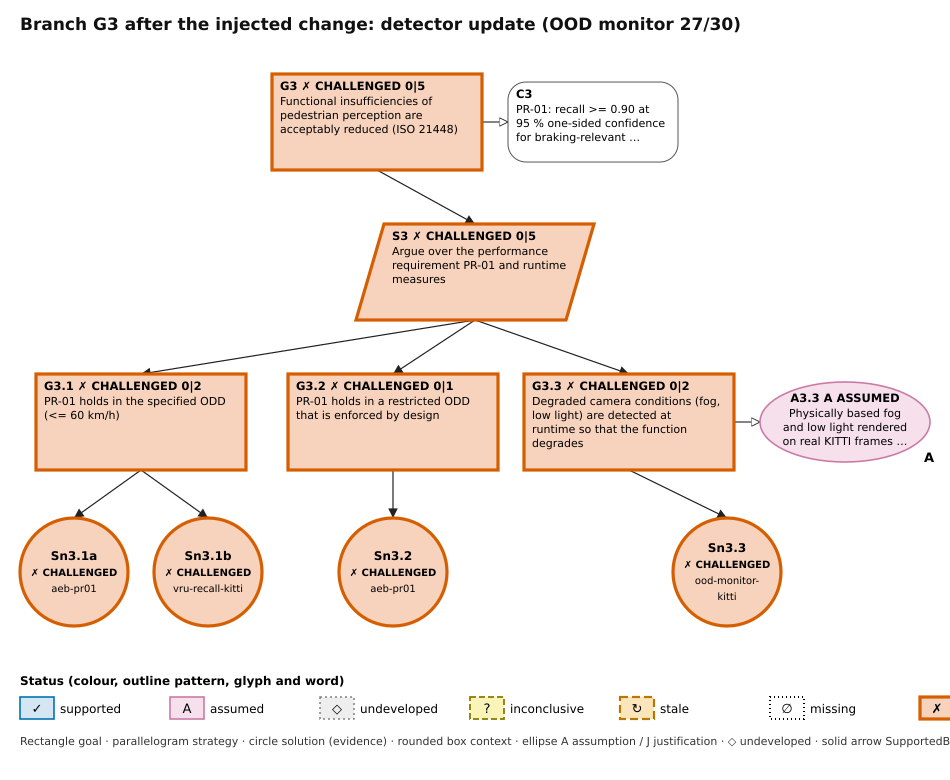

,committed,detector update (OOD monitor 27/30),dataset shift (night-time calibration),field SPI (26 VRU crashes in 167 M miles)
G3.3,assumed,challenged,assumed,assumed
G3,challenged,challenged,challenged,challenged
G4.1,supported,supported,challenged,supported
G4,challenged,challenged,challenged,challenged
G7.2,inconclusive,inconclusive,inconclusive,challenged
G7,inconclusive,inconclusive,inconclusive,challenged
G1,challenged,challenged,challenged,challenged


In [11]:
name = next(iter(SCENARIOS))
display(SVG(after[name].to_svg(root="G3", title=f"Branch G3 after the injected change: {name}")))
paths = pd.DataFrame({n: {k: v.status for k, v in e.results.items() if k in ("G1", "G3", "G3.3", "G4", "G4.1", "G7", "G7.2")}
                      for n, e in [("committed", ev)] + list(after.items())})
display(paths)

**Reading the result.** Each change flips a solution and every goal above it *up to the first ancestor that is already worse*. The top claim G1 is red before and after: a single traffic light on the top claim would show no change at all. This is why CI compares **every node**, and why a dashboard that has been red for months is not a monitoring system. The SPI case shows the role of `refute`: with 11 VRU crashes the interval straddles 0.10 and the claim is *inconclusive* (evidence too thin to decide); only when the lower bound exceeds the threshold is it *challenged*, and the response rule of [07-05](../07_Runtime_Assurance_and_Operations/05_field_safety_monitoring.ipynb) (investigate, pool, escalate) applies.

### 5.4 SPIs as evidence, and evidence that ages

The two SPI solutions carry `max_age_days: 200` relative to the end of the data window (30 June 2026). The same evidence, evaluated later without a refresh, becomes *stale* without any code change: the field loop must keep running for the claim to stay supported.

In [12]:
for day in (AS_OF, dt.date(2027, 1, 31)):
    e = case.evaluate(as_of=day)
    print(f"{day}: Sn7.1 {e['Sn7.1'].status:9s} Sn7.2 {e['Sn7.2'].status:12s} G7 {e['G7'].status:12s} | {e['Sn7.1'].reason}")

2026-10-29: Sn7.1 supported Sn7.2 inconclusive G7 inconclusive | injury_high = 0.729 <= 1.876 (injury_threshold)


2027-01-31: Sn7.1 stale     Sn7.2 stale        G7 stale        | evidence dated 2026-06-30 is older than 200 days on 2027-01-31


### 5.5 How it runs in CI on every pull request

Two jobs share the work (the full steps are in the repository's `.github/workflows/ci.yml`):

```yaml
# toolkit job: structure and freshness of the committed case (fast, no notebooks)
- name: Safety case integrity (claim statuses are reported, not enforced)
  run: python scripts/safety_case.py --check

# each module job: execute the module's notebooks, which rewrite their evidence records,
# then compare the regenerated evidence with the committed copy
- name: Keep the committed evidence
  run: cp -r safety_case/evidence "$RUNNER_TEMP/evidence-committed"
- name: Execute every notebook in the module
  run: python scripts/execute_notebooks.py --timeout 1800 $(find ${{ matrix.module }} -name '*.ipynb' | sort)
- name: Safety case: did a claim change status?
  run: python scripts/safety_case.py --diff "$RUNNER_TEMP/evidence-committed"
```

`--check` fails on *integrity* (stale or missing evidence, broken argument), never on a red claim. `--diff` fails when re-running the notebooks changes a claim's status relative to what is committed: either the results are not reproducible, or someone changed code without committing the evidence that goes with it. A deliberate change, such as a better detector, passes once its regenerated evidence is committed in the same pull request, where reviewers see the status change in the diff of `site/safety-case.md`. The next cell runs the real command on the injected detector update.

In [13]:
script = case.root / "scripts" / "safety_case.py" if case.root else None
if script is not None and script.exists():
    new_dir = Path(tempfile.mkdtemp())
    for eid, rec in SCENARIOS["detector update (OOD monitor 27/30)"].items():
        (new_dir / f"{eid}.json").write_text(json.dumps({k: v for k, v in rec.items() if not k.startswith("_")}))
    out = subprocess.run([sys.executable, str(script), "--evidence", str(new_dir), "--diff", str(case.evidence_dir),
                          "--as-of", AS_OF.isoformat()], capture_output=True, text=True)
    print(out.stdout.strip())
    print(f"exit code {out.returncode} -> the CI step fails and names the flipped claims")
else:
    print("scripts/safety_case.py is only available in a clone of the repository.")

Evidence with changed values: ood-monitor-kitti
2 claim(s) changed status:
  CLAIM FLIPPED G3.3 (Goal): assumed -> challenged: from Sn3.3
  CLAIM FLIPPED Sn3.3 (Solution): supported -> challenged: criterion not met: tpr_lower_95 = 0.761 >= 0.9
       tpr_detected: 30 -> 27
       tpr_lower_95: 0.905 -> 0.761
exit code 1 -> the CI step fails and names the flipped claims


## 6. What the automation does not do

* **Evidence is not argument validity.** The evaluator checks that each criterion is met by current evidence. Whether the criteria are the right ones, whether the strategy covers all hazards, and whether the evidence is relevant to the claim remain judgements for engineers and assessors. A well-formed, all-green case can still be wrong.
* **A green dashboard is not a safety argument.** The status table is a *view* of the argument; the reasons (strategies, justifications, assumptions) are what a reviewer must read.
* **Criteria can be gamed.** Because criteria are code, changing a threshold is a one-line diff. Treat changes to `safety_case/*.yaml` like changes to safety requirements: owner review, rationale, and never in the same pull request as the evidence they make green.
* **Hashes see code, not data.** A dataset that changes behind an unchanged URL is invisible to the code hash; record dataset versions or content hashes in the evidence when the data source is mutable.
* **Assumptions without checks stay assumptions.** A2.1 and A3.3 are honestly *assumed*; turning them into checked assumptions (a DFA result, a real-fog validation) is engineering work, not tooling.

## In industry

**Work product.** The living safety case and its evidence register, kept in configuration management with the product: the ISO 26262-2 safety case, the SOTIF argument (ISO 21448 cl. 12) and its operation-phase monitoring (cl. 13), the ISO/PAS 8800 assurance argument for AI components, and, for driverless products, a UL 4600 safety case with SPIs. The CI status report is an input to change impact analysis and to every release gate, including over-the-air updates.

**How teams do this today.** Most organisations keep requirements, tests and results in application lifecycle management (ALM) tools with trace links, and arguments in a dedicated assurance-case editor with GSN support. The weak point is the hand-over between the two: evidence is attached as a document with a date, and nobody is told when the producing pipeline changes. The pattern here closes that gap with three conventions that work in any toolchain: (1) every evidence item is produced by an automated job and carries the identity (hash, version) of what produced it; (2) acceptance criteria are stored with the claim, not with the test; (3) a CI step re-evaluates the argument and fails on integrity, and reports every status change. Field SPIs enter the same way, from the fleet-data pipeline.

**Who does what.** The safety-case owner (often the functional safety manager) owns the argument and the criteria; engineering teams own the producing jobs; the release board decides on red claims; field monitoring owns the SPIs and their response rules; an independent assessor reviews the argument and samples the evidence chain.

**What assessors look for**

- [ ] Each solution traceable to a versioned artefact for the released configuration, with the producing code identity.
- [ ] Acceptance criteria fixed before the evidence, with rationale, and under change control.
- [ ] Stale and missing evidence visible, with an owner and a date, rather than silently carried forward.
- [ ] Assumptions listed, and the critical ones checked by evidence (exchangeability, independence, ODD enforcement).
- [ ] SPIs tied to named claims, with thresholds, refresh intervals and response rules for violated and inconclusive values.
- [ ] Evidence that the automation itself is correct (tests of the evaluator) and that its outputs are reviewed, not just displayed.

**Pitfalls.** Treating the number of green nodes as safety; letting producers set their own thresholds; aggregating everything into one top-level traffic light; and automating evidence collection while leaving the argument structure unreviewed for years.

## Key takeaways

1. A safety case is valid only for a configuration; code, data, the world and time all move. Without automation it decays silently.
2. As code, an argument has three parts: GSN structure with acceptance criteria (YAML), evidence records written by the computations themselves (JSON with producer hash), and an evaluator with explicit, tested propagation rules.
3. Seven statuses keep different situations apart: *challenged* (negative evidence), *inconclusive* (evidence too thin), *stale* (evidence about a different system or time), *missing*, *undeveloped*, *assumed* and *supported*.
4. Undercutting defeaters matter: a claim can be challenged through a failed assumption while its own evidence is green (G4.3).
5. CI fails on integrity and on status changes, never merely because a claim is red; the AEB case stays honestly *do not release*.
6. UL 4600 SPIs, ISO 21448 clause 13 and ISO/PAS 8800 measures during operation all ask for the argument to be kept true after release; SPI evidence with an age limit makes that requirement executable.
7. Automation checks consistency, not adequacy: the argument still needs engineering judgement and independent assessment.

## Self-assessment

1. Name the four kinds of change that make a static safety case wrong, and the status each produces here.
2. Why must acceptance criteria be stored in the argument rather than in the notebook that measures the value?
3. In §4, G4.3's solution meets its criterion, yet G4.3 is challenged. Which rule causes this, and what kind of defeater is it?
4. Why does the top claim G1 not change in any of the injected scenarios, and why does CI therefore compare every node?
5. With 11 VRU crashes in 167 million miles the SPI is *inconclusive*. What would you do operationally, and why is "pass" the wrong answer?
6. A colleague changes only a plot in the OOD monitor notebook. What happens in CI, and is that a reasonable price?
7. Give one change that the code hash cannot detect, and how you would make it visible.

<details>
<summary>Answers</summary>

1. Producer code or model (stale via code hash), data (challenged via the criterion on regenerated evidence), the world/field (challenged or inconclusive via SPIs) and time (stale via the age limit).
2. Otherwise the party that produces the evidence also decides when it is sufficient and can, consciously or not, tune the criterion to the result. In the argument, the criterion is reviewed with the claim and changes to it are visible in version control.
3. Rule P3 (with P2): a goal takes the worst status of its supporting children *and* its InContextOf assumptions. Assumption A4.3 (exchangeability) is checked by the coverage on truncated objects (0.30 < 0.88) and fails: an undercutting defeater, since it attacks the inference from the evidence to the claim rather than the evidence itself.
4. G1 is already challenged by G3.1, G4.2 and G5, and statuses propagate as the worst child. A top-level indicator therefore hides new defeaters; comparing every node shows which claim newly failed and why.
5. Treat it as an open item: pool further data, investigate the 11 crashes (narratives, causes), and decide in advance at what count or rate the response escalates. "Pass" is wrong because the interval includes rates above the threshold; the evidence cannot exclude a violation.
6. The notebook's code hash changes, all its evidence becomes stale, `--check` fails until the notebook is executed and the evidence committed (`--diff` then confirms no status changed). It costs one notebook run; the alternative, judging which code changes "matter", is exactly the judgement that fails silently.
7. A dataset that is updated in place at the same URL, or a model file downloaded by name without a version. Record a content hash or version of the data and weights in the evidence values, and add it to the criterion or to the staleness check.
</details>

## References

1. Assurance Case Working Group (2021). *Goal Structuring Notation Community Standard*, Version 3, SCSC-141C. Safety-Critical Systems Club. https://scsc.uk/gsn
2. UL Standards & Engagement (2023). *UL 4600: Standard for Safety for the Evaluation of Autonomous Products*, 3rd ed. https://ulse.org/ul-standards-engagement/autonomous-vehicle-technology/
3. Koopman, P. (2023). UL 4600: What to include in an autonomous vehicle safety case. *Computer*, 56(5), 101–104. https://doi.org/10.1109/MC.2023.3236171
4. Koopman, P. (2022). *A safety case + SPI metric approach for autonomous vehicle safety* (lecture slides). Carnegie Mellon University. https://users.ece.cmu.edu/~koopman/lectures/L125_SPI_Monitoring.pdf
5. Ratiu, D., Rohlinger, T., Stolte, T., Wagner, S. (2024). Towards an argument pattern for the use of safety performance indicators. In *Computer Safety, Reliability, and Security. SAFECOMP 2024 Workshops*, LNCS, 160–172. Springer. https://doi.org/10.1007/978-3-031-68738-9_12
6. ISO/TS 5083:2025. *Road vehicles — Safety for automated driving systems — Design, verification and validation*. https://www.iso.org/standard/81920.html
7. ISO 21448:2022. *Road vehicles — Safety of the intended functionality*. https://www.iso.org/standard/77490.html
8. ISO/PAS 8800:2024. *Road vehicles — Safety and artificial intelligence*. https://www.iso.org/standard/83303.html
9. Denney, E., Pai, G., Habli, I. (2015). Dynamic safety cases for through-life safety assurance. *Proc. 37th IEEE/ACM International Conference on Software Engineering (ICSE)*, 587–590. https://doi.org/10.1109/ICSE.2015.199
10. Goodenough, J. B., Weinstock, C. B., Klein, A. Z. (2013). Eliminative induction: A basis for arguing system confidence. *Proc. 35th International Conference on Software Engineering (ICSE)*, 1161–1164. https://doi.org/10.1109/ICSE.2013.6606668
11. Bloomfield, R., Rushby, J. (2020). Assurance 2.0: A manifesto. arXiv:2004.10474. https://arxiv.org/abs/2004.10474
12. Patel, M., Jung, R. (2026). Integrating cybersecurity into the AI safety assurance argument: A GSN pattern for AI-based perception components in highly automated driving. In *Computer Safety, Reliability, and Security. SAFECOMP 2026 Workshops*, LNCS, 763–779. Springer. https://doi.org/10.1007/978-3-032-35506-5_55

---
**Navigation:** ← [05 Capstone: pedestrian AEB from requirement to release](05_capstone_aeb_from_requirement_to_release.ipynb) · [Module index](README.md) · [Course overview](../README.md) →